# Walkthrough：巴黎月最高气温预测（动手路线）

这个 notebook 按 `TUTORIAL.md` 第 3.1 节的顺序，一步步调用 `src/` 里的模块。
每个练习都是同一个节奏：**先在纸上写下你的预测 → 再运行 → 对照"检查点"**。

- 运行方式：在仓库根目录 `.venv/bin/pip install jupyterlab`，然后 `jupyter lab notebooks/walkthrough.ipynb`
  （或用 VS Code 打开并选择 `.venv` 内核）。
- 完整实验（约 2 分钟）不在这里跑，用 `make all`；本 notebook 最后一节直接读取 `results/` 里的结果。

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from src.data import load_montsouris, load_original, TRUTH_2025_PDF, TRUTH_2025_CODE
from src.ar import lag_matrix, all_subsets, search_subsets, max_root_modulus
from src.models import SeasonalNaive, Climatology, LagAR
from src.evaluate import rolling_origin, replay_original_protocol, metrics

np.set_printoptions(precision=2, suppress=True)
s = load_montsouris()          # official Météo-France series, 1950-01 .. 2026-10
y = load_original()            # data2.csv from the course, 2023-01 .. 2024-12
truth = np.array(TRUTH_2025_PDF)
mae = lambda pred, t=truth: round(float(np.mean(np.abs(np.asarray(pred) - t))), 2)

## 练习 1 数据核对
**先预测**：课程给的 `data2.csv`（24 个值）里，有几个和蒙苏里站官方 `TX` 完全相同？2025 年 1–4 月官方值是多少？
再猜：原始温度"今年 1 月和去年 1 月"的相关系数（lag-12 自相关）高吗？去掉季节平均之后呢？

In [2]:
print(len(s), "months:", s.index[0].date(), "->", s.index[-1].date())
print("data2.csv == Montsouris TX:", int((s.loc[y.index] == y).sum()), "/ 24")
print("Jan-Apr 2025 (official):", s.loc["2025-01":"2025-04"].to_numpy())

# trend: annual means of complete years
annual = s.groupby(s.index.year).mean()[s.groupby(s.index.year).size() == 12]
for a, b in [(1951, 1980), (1991, 2020), (2016, 2025)]:
    print(f"annual mean TX {a}-{b}: {annual.loc[a:b].mean():.2f} °C")
# seasonality vs anomalies (1991-2020)
n = s["1991":"2020"]
clim = n.groupby(n.index.month).mean()
anom = n - clim.loc[n.index.month].to_numpy()
print("seasonal amplitude (Jul - Jan normal):", round(clim[7] - clim[1], 1), "°C | anomaly std:", round(anom.std(), 2))
print("autocorrelation raw:       lag1 =", round(n.autocorr(1), 3), " lag12 =", round(n.autocorr(12), 3))
print("autocorrelation anomalies: lag1 =", round(anom.autocorr(1), 3), " lag12 =", round(anom.autocorr(12), 3))

922 months: 1950-01-01 -> 2026-10-01
data2.csv == Montsouris TX: 24 / 24
Jan-Apr 2025 (official): [ 7.5  8.6 14.6 20. ]
annual mean TX 1951-1980: 15.04 °C
annual mean TX 1991-2020: 16.48 °C
annual mean TX 2016-2025: 17.45 °C
seasonal amplitude (Jul - Jan normal): 18.1 °C | anomaly std: 1.84
autocorrelation raw:       lag1 = 0.811  lag12 = 0.924
autocorrelation anomalies: lag1 = 0.197  lag12 = -0.045


## 练习 2 自己算季节性朴素基线（seasonal naive）
规则：预测值 = 去年同月。**先预测**：用官方真实值算 MAE 是多少？用代码里的 8/10/14/18 呢？

In [3]:
snaive = y.loc["2024-01":"2024-04"].to_numpy()   # = SeasonalNaive().forecast(y, 4)
print("forecast:", snaive)
print("MAE vs official:", mae(snaive), "| MAE vs code values:", mae(snaive, np.array(TRUTH_2025_CODE)))

forecast: [ 7.6 11.9 14.3 16.9]
MAE vs official: 1.7 | MAE vs code values: 0.93


## 练习 3 数一数原项目的穷举
**先预测**：12 个滞后有多少个非空子集？只有 12 行训练数据时，有多少个子集真的能拟合（至少留 1 个残差自由度）？

In [4]:
table = search_subsets(y.to_numpy())          # one OLS per subset
X, target = lag_matrix(y.to_numpy())
print("subsets:", len(all_subsets(12)), "| fitted:", len(table), "| training matrix:", X.shape)
print("fitted subsets by size:", table["n_lags"].value_counts().sort_index().to_dict())

subsets: 4095 | fitted: 4082 | training matrix: (12, 12)
fitted subsets by size: {1: 12, 2: 66, 3: 220, 4: 495, 5: 792, 6: 924, 7: 792, 8: 495, 9: 220, 10: 66}


## 练习 4 去掉 p 值筛选；改用 AIC / BIC
原规则 = "调整 R² 最大，且所有斜率 p < 0.05"。**先预测**：去掉 p 值条件、或改用 AIC/BIC 后，会选更少还是更多滞后？

In [5]:
for crit in ["original", "adj_r2", "aic", "bic"]:
    m = LagAR(crit).fit(y)
    f = m.forecast(y, 4)
    print(f"{crit:9s} lags={m.lags} adjR2={m.res.rsquared_adj:.5f} "
          f"df_resid={m.res.df_resid:.0f} forecast={f.round(2)} MAE={mae(f)}")

original  lags=(1, 2, 5, 7, 8, 9, 10, 11, 12) adjR2=0.99967 df_resid=2 forecast=[ 7.95  8.65 11.96 18.91] MAE=1.06
adj_r2    lags=(1, 2, 5, 6, 7, 8, 9, 10, 11, 12) adjR2=0.99998 df_resid=1 forecast=[ 7.82  8.33 11.81 19.3 ] MAE=1.02
aic       lags=(1, 2, 5, 6, 7, 8, 9, 10, 11, 12) adjR2=0.99998 df_resid=1 forecast=[ 7.82  8.33 11.81 19.3 ] MAE=1.02
bic       lags=(1, 2, 5, 6, 7, 8, 9, 10, 11, 12) adjR2=0.99998 df_resid=1 forecast=[ 7.82  8.33 11.81 19.3 ] MAE=1.02


## 练习 5 在纯噪声上跑原来的选模规则（多重比较 / 选择偏差）
用 20 条完全随机的序列（白噪声，没有任何可预测的结构，长度 24 个月，和 data2.csv 一样），
跑一遍"穷举 4,095 个组合 + 调整 R² 最大 + 所有 p < 0.05"。
**先预测**：有几条噪声序列会被"找到"一个所有系数都显著的模型？它们的调整 R² 会有多高？

In [6]:
from src.ar import select_lags
rows = []
for seed in range(20):
    noise = np.random.default_rng(seed).normal(0, 1, 24)
    t = search_subsets(noise)
    ok = t[t["max_p"] < 0.05]
    rows.append(dict(seed=seed, n_all_significant=len(ok),
                     best_adj_r2=ok["adj_r2"].max() if len(ok) else np.nan))
noise_runs = pd.DataFrame(rows)
print("noise series with >= 1 'all p < 0.05' model:", int((noise_runs["n_all_significant"] > 0).sum()), "/ 20")
print("... of which adjusted R2 > 0.9:", int((noise_runs["best_adj_r2"] > 0.9).sum()))
print("median best adjusted R2:", round(noise_runs["best_adj_r2"].median(), 4))

noise series with >= 1 'all p < 0.05' model: 17 / 20
... of which adjusted R2 > 0.9: 15
median best adjusted R2: 0.9994


## 练习 6 把最大滞后改成 6
**先预测**：训练行数会变吗？选出的模型会更简单吗？

In [7]:
m6 = LagAR("original", max_lag=6).fit(y)
f6 = m6.forecast(y, 4)
print("subsets:", len(all_subsets(6)), "| training rows:", int(m6.res.nobs))
print("lags:", m6.lags, "| adjR2:", round(m6.res.rsquared_adj, 4), "| df_resid:", m6.res.df_resid)
print("forecast:", f6.round(2), "| MAE:", mae(f6))

subsets: 63 | training rows: 18
lags: (1, 4) | adjR2: 0.884 | df_resid: 15.0
forecast: [ 9.11 10.98 15.4  20.01] | MAE: 1.2


## 练习 7 画残差图（residuals）
对比两个模型：12 行训练的原模型，和用 1995–2024 共 30 年训练的同一规则。
**先预测**：哪个模型的样本内残差更小？30 年模型的残差在各月份是否一样大？

12-row model: max |resid| = 0.089 | in-sample RMSE = 0.048


30-year model: (1, 4, 6, 8, 11, 12) | rows: 348 | in-sample RMSE: 1.99
residual std by month: {1: 1.81, 2: 2.61, 3: 1.71, 4: 2.18, 5: 1.93, 6: 1.66, 7: 2.02, 8: 2.27, 9: 2.09, 10: 1.72, 11: 1.76, 12: 1.8}
mean residual by decade: {1990: -0.28, 2000: -0.22, 2010: 0.09, 2020: 0.49}


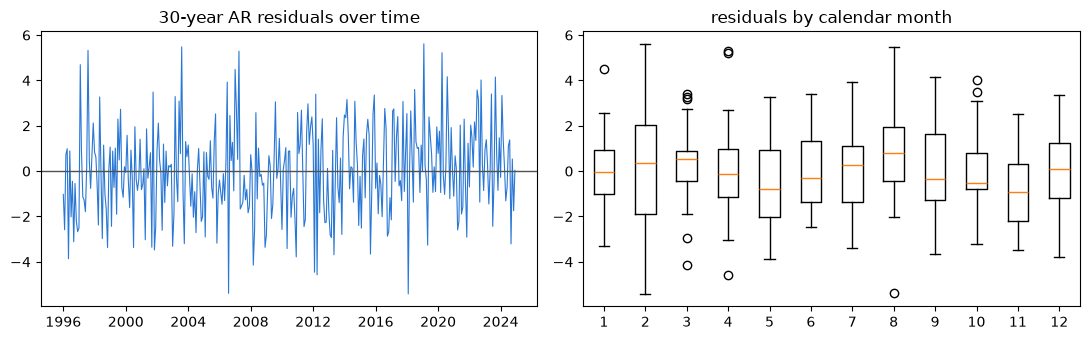

In [8]:
m12 = LagAR("original").fit(y)
print("12-row model: max |resid| =", round(float(np.abs(m12.res.resid).max()), 3),
      "| in-sample RMSE =", round(m12.insample_rmse, 3))

train30 = s.loc["1995-01":"2024-12"]
m30 = LagAR("original").fit(train30)
resid = pd.Series(m30.res.resid, index=train30.index[12:])
print("30-year model:", m30.lags, "| rows:", int(m30.res.nobs), "| in-sample RMSE:", round(m30.insample_rmse, 2))
print("residual std by month:", resid.groupby(resid.index.month).std().round(2).to_dict())
print("mean residual by decade:", resid.groupby(resid.index.year // 10 * 10).mean().round(2).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(resid.index, resid, lw=0.8, color="#2a78d6")
ax[0].axhline(0, color="#52514e", lw=1)
ax[0].set_title("30-year AR residuals over time")
resid.groupby(resid.index.month).apply(list).pipe(lambda g: ax[1].boxplot(list(g), tick_labels=list(g.index)))
ax[1].set_title("residuals by calendar month")
plt.tight_layout(); plt.show()

## 练习 8 把原方法放到别的年份
**先预测**：如果课程是 1990 年或 2020 年开的（用前两年训练、预测 1–4 月），原 AR 的 MAE 会是多少？

In [9]:
rp, fits = replay_original_protocol(s, [1990, 2020, 2025])
by_year = (rp.assign(ae=(rp.y_pred - rp.y_true).abs())
             .groupby(["year", "method"])["ae"].mean().unstack().round(2))
display(by_year)
display(fits.round(4))

method,ar_original,climatology_30y,linear_trend_q12,seasonal_naive,two_year_mean
year,,,,,
1990,471.65,2.86,16.08,1.72,1.74
2020,37.60,2.62,16.12,2.07,1.98
2025,1.06,1.46,16.48,1.70,1.91


,year,lags,n_lags,adj_r2,insample_rmse,max_root
0,1990,"(1, 2, 3, 4, 5, 6, 9, 10, 11, 12)",10,0.9998,0.0255,3.5578
1,2020,"(1, 2, 3, 4, 5, 6, 7, 9, 10, 12)",10,1.0000,0.0008,2.7953
2,2025,"(1, 2, 5, 7, 8, 9, 10, 11, 12)",9,0.9997,0.0482,1.0537


## 练习 9 递推预测：误差为什么会累积
递推（recursive）= 2 月的预测要用 1 月的**预测值**当输入。对比"每个月都用真实的上月值做一步预测"。
**先预测**：哪一年递推会出大问题？`max_root_modulus` > 1 说明什么？

In [10]:
for year in [2025, 1990]:
    train = s.loc[f"{year-2}-01":f"{year-1}-12"]
    m = LagAR("original").fit(train)
    rec = m.forecast(train, 4)
    one_step = np.array([m.forecast(s.loc[:o], 1)[0]
                         for o in pd.date_range(f"{year-1}-12-01", periods=4, freq="MS")])
    tt = s.loc[f"{year}-01":f"{year}-04"].to_numpy()
    print(year, "max|root| =", round(max_root_modulus(m.lags, m.params), 3))
    print("   truth    ", tt)
    print("   recursive", rec.round(2), "|err|", np.abs(rec - tt).round(2))
    print("   one-step ", one_step.round(2), "|err|", np.abs(one_step - tt).round(2))

2025 max|root| = 1.054
   truth     [ 7.5  8.6 14.6 20. ]
   recursive [ 7.95  8.65 11.96 18.91] |err| [0.45 0.05 2.64 1.09]
   one-step  [ 7.95  8.   12.32 22.77] |err| [0.45 0.6  2.28 2.77]
1990 max|root| = 3.558
   truth     [ 8.4 13.6 14.3 14.6]
   recursive [   31.59   -98.95   396.29 -1354.28] |err| [  23.19  112.55  381.99 1368.88]
   one-step  [ 31.59 -11.48 -15.32  -1.74] |err| [23.19 25.08 29.62 16.34]


## 练习 10 一个最小的滚动评估（rolling-origin）
2001–2026 每个月做一次预测起点，用前 30 年训练，预测未来 1–4 个月。
**先预测**：季节性朴素和 30 年气候平均谁更准？两者 RMSE 之比大概是多少（提示：√2）？

In [11]:
fc, _ = rolling_origin(s, {"seasonal_naive": SeasonalNaive, "climatology_30y": Climatology},
                       first_origin="2000-12-01", last_origin="2026-09-01", window=360)
m = metrics(fc, by=("method", "h"))
display(m[["MAE", "RMSE"]].unstack().round(3))
print("RMSE ratio (h=1):", round(m.loc[("seasonal_naive", 1), "RMSE"] / m.loc[("climatology_30y", 1), "RMSE"], 3),
      "| sqrt(2) =", round(np.sqrt(2), 3))

MAE                        RMSE                     
h                    1      2      3      4      1      2      3      4
method                                                                 
climatology_30y  1.619  1.620  1.622  1.624  2.025  2.027  2.030  2.031
seasonal_naive   2.120  2.124  2.126  2.133  2.660  2.664  2.667  2.672

RMSE ratio (h=1): 1.314 | sqrt(2) = 1.414


## 完整结果（来自 `make all`，这里只读取）

In [12]:
R = ROOT / "results"
display(Markdown("**2025 ex-post**"))
display(pd.read_csv(R / "02_expost_2025.csv", index_col=0).round(2))
display(Markdown("**Replay of the original protocol, 1980-2026**"))
display(pd.read_csv(R / "03_replay_metrics.csv", index_col=0).round(2))
display(Markdown("**Rolling-origin MAE by horizon (30-year window)**"))
display(pd.read_csv(R / "04_rolling_metrics.csv", index_col=[0, 1])["MAE"].unstack().round(3))

**2025 ex-post**

,block,Jan,Feb,Mar,Apr,MAE_official,RMSE_official,MAE_code,RMSE_code
method,,,,,,,,,
ar_original_9lags,as in the project,7.95,8.65,11.96,18.91,1.06,1.45,1.09,1.30
linear_trend_q12,as in the project,3.06,-1.52,-6.10,-10.68,16.48,19.31,16.31,18.60
seasonal_naive,as in the project,7.60,11.90,14.30,16.90,1.70,2.27,0.93,1.13
two_year_mean,as in the project,7.95,11.25,13.80,16.25,1.91,2.34,0.81,1.08
normals_1991_2020,as in the project,7.61,8.83,12.79,16.56,1.40,1.95,1.05,1.12
climatology_30y,"backtest model, trained 1995-2024",7.58,9.32,12.90,16.68,1.46,1.90,0.88,0.95
ar_original,"backtest model, trained 1995-2024",8.68,10.29,13.54,16.79,1.79,1.98,0.66,0.75
ar_adj_r2,"backtest model, trained 1995-2024",8.71,10.32,13.48,16.69,1.84,2.04,0.72,0.81
ar_aic,"backtest model, trained 1995-2024",8.68,10.29,13.54,16.79,1.79,1.98,0.66,0.75


**Replay of the original protocol, 1980-2026**

,MAE,RMSE,MedAE,bias,n,years_AR_better
method,,,,,,
ar_original,27.52,115.25,4.80,-5.74,188,NaN
climatology_30y,1.76,2.18,1.56,-0.71,188,3.0
linear_trend_q12,15.54,18.20,14.35,-15.42,188,34.0
seasonal_naive,2.30,2.95,1.95,-0.13,188,7.0
two_year_mean,1.97,2.49,1.65,-0.17,188,4.0


**Rolling-origin MAE by horizon (30-year window)**

h,1,2,3,4
method,,,,
anomaly_ar,1.521,1.583,1.595,1.620
ar_adj_r2,1.692,1.855,1.880,1.903
ar_aic,1.692,1.851,1.881,1.900
ar_bic,1.686,1.852,1.880,1.900
ar_cv,1.648,1.816,1.829,1.848
ar_original,1.692,1.845,1.876,1.897
climatology_30y,1.619,1.620,1.622,1.624
sarima,1.529,1.590,1.599,1.605
seasonal_naive,2.120,2.124,2.126,2.133


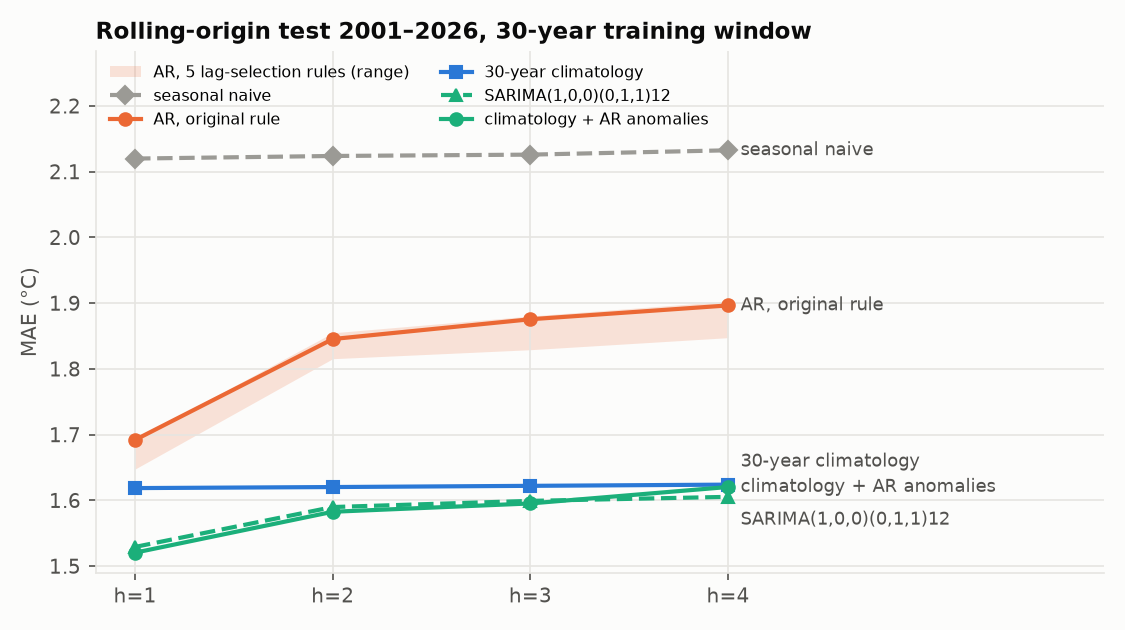

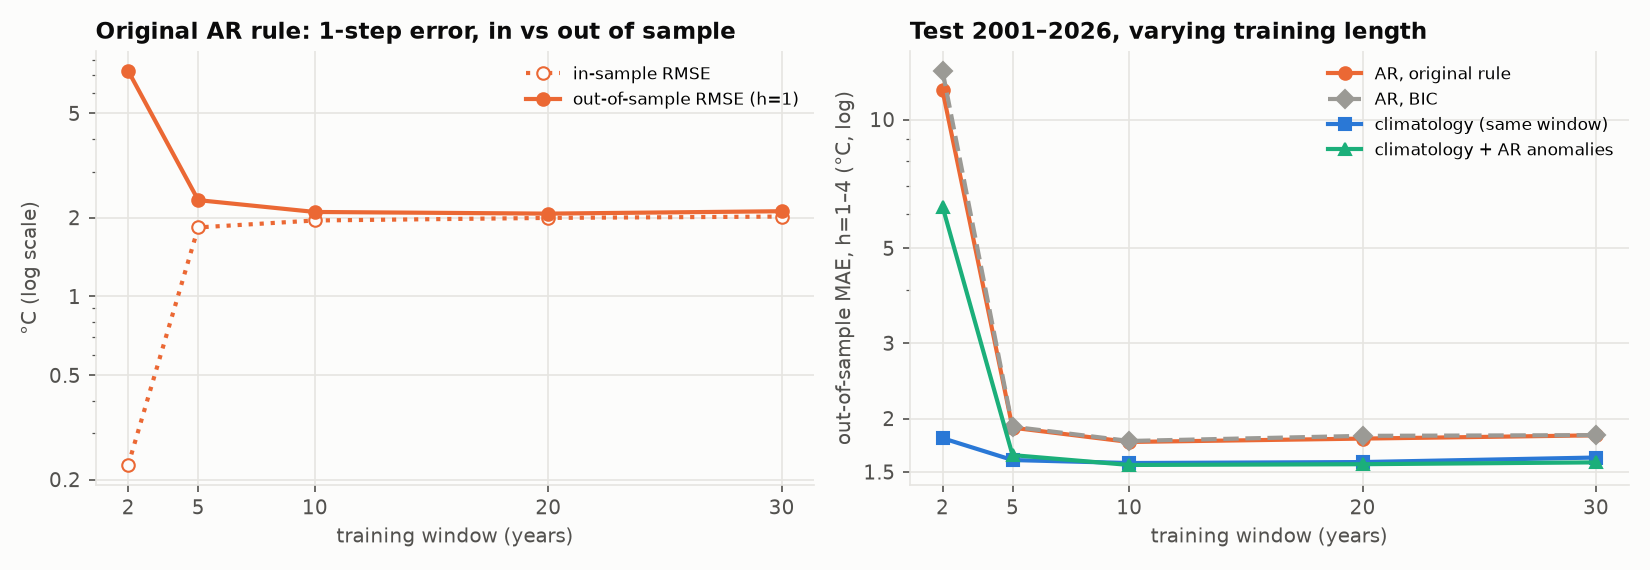

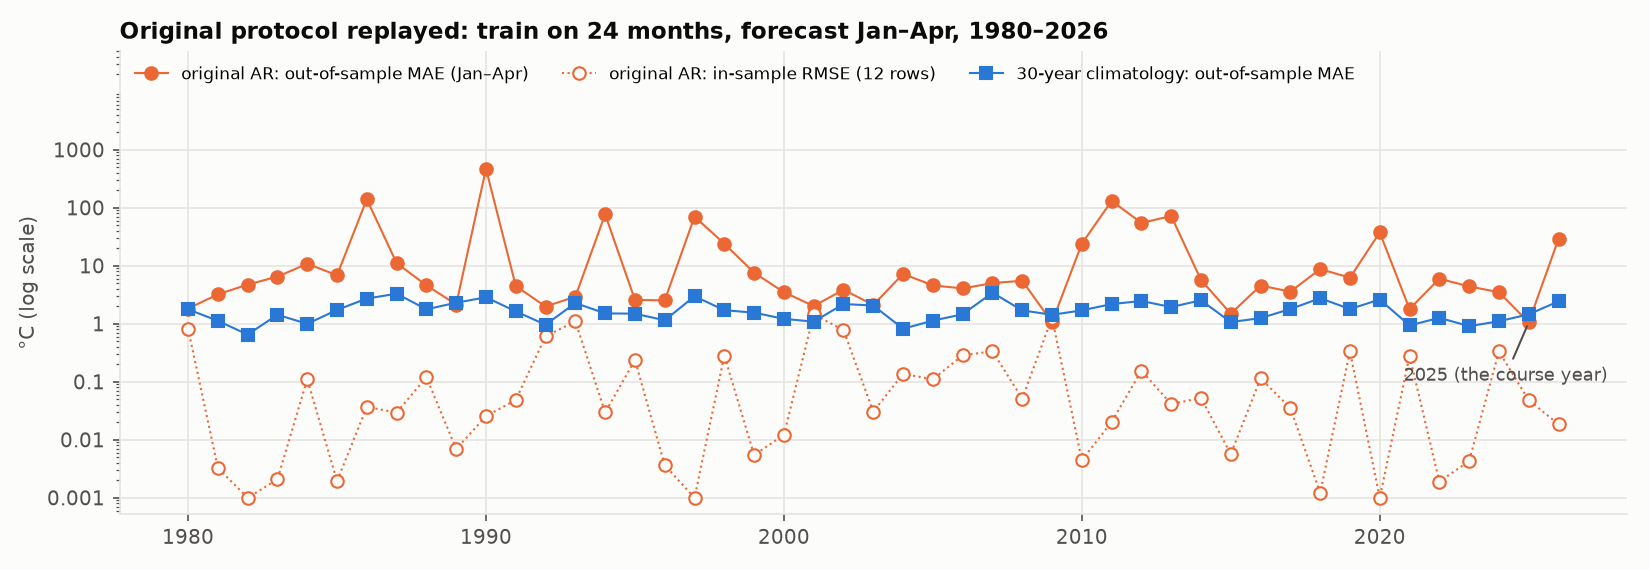

In [13]:
for f in ["fig4_rolling_mae_by_horizon.png", "fig5_window_sweep.png", "fig3_replay_original_protocol.png"]:
    display(Image(filename=str(R / f), width=850))